# PT-05 - Análise discriminante: LDA, QDA e ROC manual

**Valentim Soares de Andrade Neto - 2019027210**

Resolução de `Aula 12 - Exercício Análise Discriminantes e ROC.pdf`.
São comparados o cenário original e o deslocamento da média da classe 1 para
$(3,3)$. **Classe 1 = rótulo 0 (azul); classe 2 = rótulo 1 (vermelho)**.
A classe positiva das curvas ROC é, portanto, a **classe 2**.

O termo “precisão” do enunciado é tratado como **acurácia**, conforme seu
código: proporção total de previsões corretas. Não se confunde com o valor
preditivo positivo, $TP/(TP+FP)$.


In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

OUTPUT = Path('output')
FIGURAS = OUTPUT / 'figuras'
FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.precision', 6)
CORES = ['#2563eb', '#dc2626']

def salvar(fig, nome):
    fig.tight_layout()
    fig.savefig(FIGURAS / f'{nome}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## Parte 1 - Geração e visualização

Usamos $n=300$ e a semente 42, com a mesma sequência aleatória do enunciado.
A classe 1 tem 300 amostras de uma normal de média $(0,0)$ e covariância
$\left[\begin{smallmatrix}1&0.8\\0.8&1\end{smallmatrix}\right]$.
A classe 2 tem 600 amostras: 300 de média $(-2,-2)$ e covariância
$\left[\begin{smallmatrix}1&-0.6\\-0.6&1\end{smallmatrix}\right]$ e 300 de
média $(-2,1.5)$ e covariância
$\left[\begin{smallmatrix}1&0.6\\0.6&1\end{smallmatrix}\right]$.

A classe 2 é uma **mistura de duas gaussianas**, não duas classes distintas.
Há sobreposição: o título “linearmente separáveis” do exemplo não descreve
adequadamente estes dados. Nenhuma separação perfeita é assumida.


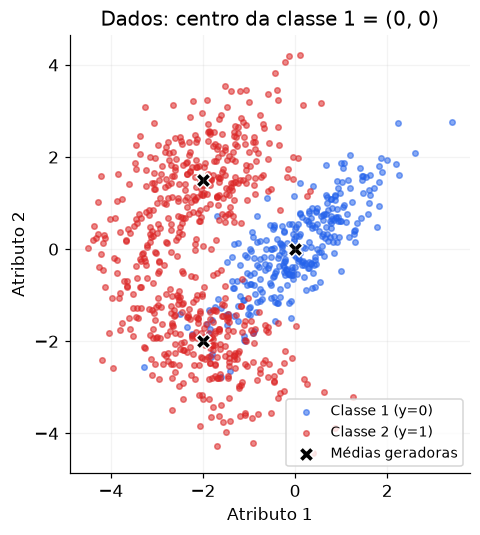

In [2]:
n = 300
rng = np.random.RandomState(42)
data_class1 = rng.multivariate_normal([0, 0], [[1, .8], [.8, 1]], n)
data_class2a = rng.multivariate_normal([-2, -2], [[1, -.6], [-.6, 1]], n)
data_class2b = rng.multivariate_normal([-2, 1.5], [[1, .6], [.6, 1]], n)
data_class2 = np.vstack((data_class2a, data_class2b))
X = np.vstack((data_class1, data_class2))
y = np.concatenate((np.zeros(n, dtype=int), np.ones(2*n, dtype=int)))

def dispersao(ax, dados, rotulos):
    for classe, cor in enumerate(CORES):
        pontos = dados[rotulos == classe]
        ax.scatter(pontos[:, 0], pontos[:, 1], c=cor, s=13, alpha=.55,
                   label=f'Classe {classe + 1} (y={classe})')
    ax.set(xlabel='Atributo 1', ylabel='Atributo 2')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=.15)

def grafico_dados(dados, nome, centro):
    fig, ax = plt.subplots(figsize=(8, 5))
    dispersao(ax, dados, y)
    medias = np.array([centro, [-2, -2], [-2, 1.5]])
    ax.scatter(medias[:, 0], medias[:, 1], marker='X', s=95,
               c='black', edgecolors='white', label='Médias geradoras')
    ax.set_title(f'Dados: centro da classe 1 = {centro}')
    ax.legend(loc='best', fontsize=9)
    salvar(fig, f'{nome}_dados')

grafico_dados(X, 'original', (0, 0))


## Parte 2 - Treinamento e avaliação

Divisão 70%/30%, `random_state=42`, sem estratificação, como no exemplo.
Os índices são fixados antes do deslocamento. Cada modelo é ajustado apenas
nas 630 observações de treino e avaliado nas 270 de teste. As probabilidades
a priori são estimadas pelo modelo a partir do treino.

LDA usa uma covariância comum e produz uma fronteira linear. QDA estima uma
covariância para cada classe e permite uma fronteira quadrática. As figuras
mostram ambos os contornos no mesmo gráfico, com os dados de teste.


,Total,Treino,Teste
Classe 1 (y=0),300,217,83
Classe 2 (y=1),600,413,187


,Acurácia,TP,FP,TN,FN
Modelo,,,,,
LDA,0.844444,165,20,63,22
QDA,0.940741,187,16,67,0


Baseline majoritária no teste: 69.26%


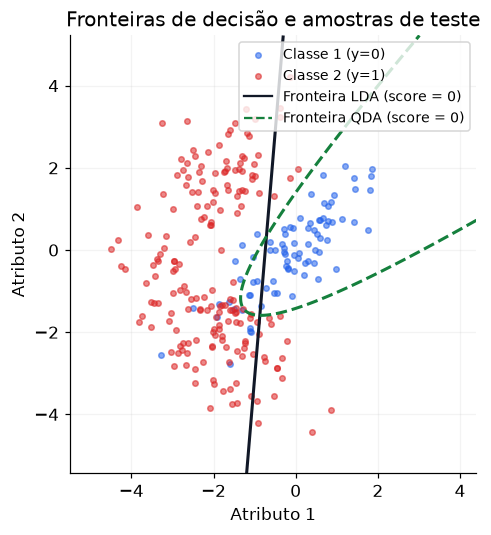

In [3]:
treino, teste = train_test_split(np.arange(len(y)), test_size=.3, random_state=42)
contagens = pd.DataFrame({
    'Total': np.bincount(y), 'Treino': np.bincount(y[treino]),
    'Teste': np.bincount(y[teste]),
}, index=['Classe 1 (y=0)', 'Classe 2 (y=1)'])
display(contagens)

def ajustar(dados):
    modelos = {'LDA': LinearDiscriminantAnalysis(),
               'QDA': QuadraticDiscriminantAnalysis()}
    for modelo in modelos.values():
        modelo.fit(dados[treino], y[treino])
    return modelos

def contagem_binaria(verdade, previsao):
    return {chave: int(np.sum((verdade == real) & (previsao == pred)))
            for chave, real, pred in [('TP', 1, 1), ('FP', 0, 1),
                                      ('TN', 0, 0), ('FN', 1, 0)]}

def metricas(dados, modelos):
    linhas = []
    for nome, modelo in modelos.items():
        pred = modelo.predict(dados[teste])
        contagem = contagem_binaria(y[teste], pred)
        linhas.append({'Modelo': nome, 'Acurácia': float(np.mean(pred == y[teste])), **contagem})
    return pd.DataFrame(linhas).set_index('Modelo')

def fronteiras(dados, modelos, nome):
    x1 = np.linspace(dados[:, 0].min()-1, dados[:, 0].max()+1, 350)
    x2 = np.linspace(dados[:, 1].min()-1, dados[:, 1].max()+1, 350)
    xx, yy = np.meshgrid(x1, x2)
    grade = np.column_stack((xx.ravel(), yy.ravel()))
    fig, ax = plt.subplots(figsize=(8, 5))
    dispersao(ax, dados[teste], y[teste])
    for (modelo_nome, modelo), cor, estilo in zip(modelos.items(), ['#111827', '#15803d'], ['-', '--']):
        scores = modelo.decision_function(grade).reshape(xx.shape)
        ax.contour(xx, yy, scores, levels=[0], colors=[cor], linestyles=[estilo], linewidths=2)
        ax.plot([], [], color=cor, linestyle=estilo, label=f'Fronteira {modelo_nome} (score = 0)')
    ax.set_title('Fronteiras de decisão e amostras de teste')
    ax.legend(fontsize=9)
    salvar(fig, f'{nome}_fronteiras')

modelos_original = ajustar(X)
metricas_original = metricas(X, modelos_original)
display(metricas_original)
print(f'Baseline majoritária no teste: {np.mean(y[teste] == 1):.2%}')
fronteiras(X, modelos_original, 'original')


## Parte 3.1 - ROC calculada manualmente

O score é obtido por `decision_function`. Para cada limiar $t$, prevemos
$y=1$ se $score\geq t$, contamos TP, FP, TN e FN, e calculamos
$TPR=TP/(TP+FN)$ e $FPR=FP/(FP+TN)$.

Não usamos funções prontas de ROC ou AUC. Percorremos **todos os scores
distintos em ordem decrescente**, além de $+\infty$. Isso inclui os extremos
$(0,0)$ e $(1,1)$ e trata empates em conjunto, evitando a perda de pontos
que pode ocorrer com apenas 100 limiares igualmente espaçados. A AUC é a
soma manual dos trapézios entre pontos consecutivos. O limiar padrão 0 é
destacado; não escolhemos limiar usando o teste.


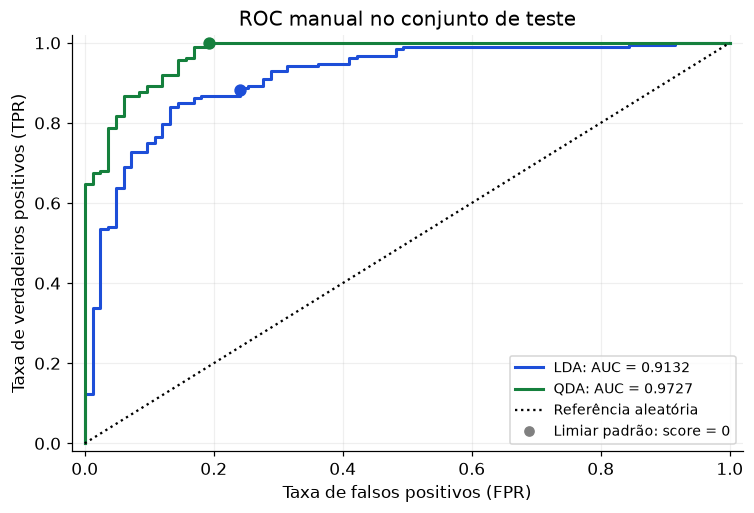

,Acurácia,TP,FP,TN,FN,AUC manual
Modelo,,,,,,
LDA,0.844444,165,20,63,22,0.913214
QDA,0.940741,187,16,67,0,0.972747


In [4]:
def roc_manual(verdade, scores):
    verdade = np.asarray(verdade)
    scores = np.asarray(scores, dtype=float)
    if verdade.ndim != 1 or scores.shape != verdade.shape or not len(scores):
        raise ValueError('Rótulos e scores devem ser vetores não vazios de mesmo tamanho.')
    if not np.all(np.isfinite(scores)) or set(np.unique(verdade)) != {0, 1}:
        raise ValueError('São necessários scores finitos e ambas as classes 0 e 1.')
    limiares = np.r_[np.inf, np.unique(scores)[::-1]]
    linhas = []
    for limiar in limiares:
        c = contagem_binaria(verdade, (scores >= limiar).astype(int))
        linhas.append({'Limiar': limiar, **c,
                       'TPR': c['TP'] / (c['TP'] + c['FN']),
                       'FPR': c['FP'] / (c['FP'] + c['TN'])})
    curva = pd.DataFrame(linhas)
    fpr, tpr = curva.FPR.to_numpy(), curva.TPR.to_numpy()
    auc = float(np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2))
    return curva, auc

def comparar_roc(dados, modelos, nome, resumo):
    fig, ax = plt.subplots(figsize=(7, 4.8))
    for (modelo_nome, modelo), cor in zip(modelos.items(), ['#1d4ed8', '#15803d']):
        scores = modelo.decision_function(dados[teste])
        curva, auc = roc_manual(y[teste], scores)
        curva.to_csv(OUTPUT / f'{nome}_roc_{modelo_nome.lower()}.csv', index=False)
        resumo.loc[modelo_nome, 'AUC manual'] = auc
        ax.plot(curva.FPR, curva.TPR, color=cor, lw=2,
                label=f'{modelo_nome}: AUC = {auc:.4f}')
        c = contagem_binaria(y[teste], (scores >= 0).astype(int))
        ax.scatter(c['FP']/(c['FP']+c['TN']), c['TP']/(c['TP']+c['FN']),
                   c=cor, marker='o', s=50, zorder=5)
    ax.plot([0, 1], [0, 1], 'k:', label='Referência aleatória')
    ax.plot([], [], 'o', color='gray', label='Limiar padrão: score = 0')
    ax.set(xlim=(-.02, 1.02), ylim=(-.02, 1.02), xlabel='Taxa de falsos positivos (FPR)',
           ylabel='Taxa de verdadeiros positivos (TPR)', title='ROC manual no conjunto de teste')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(alpha=.2)
    salvar(fig, f'{nome}_roc')
    return resumo

metricas_original = comparar_roc(X, modelos_original, 'original', metricas_original)
display(metricas_original)


## Parte 3.2 e 3.3 - Comparação e hipóteses

QDA pode acompanhar a orientação e a dispersão distintas das classes, enquanto
LDA impõe uma reta. A adequação visual deve ser confrontada com os resultados
de teste abaixo. A classe 2 é bimodal: **nem LDA nem QDA representa exatamente
sua distribuição**, pois ambos assumem uma gaussiana por classe.

**Quando preferir LDA:** classes com covariâncias semelhantes, fronteira
aproximadamente linear, poucas amostras ou muitas variáveis. Compartilhar a
covariância reduz a quantidade de parâmetros e a variância da estimativa.
Exemplo: classificação de medições de sensores com dispersões semelhantes.

**Quando preferir QDA:** covariâncias diferentes, fronteiras curvas e amostras
suficientes em cada classe. Exemplo: controle de qualidade com grupos de peças
que apresentam diferentes correlações entre medidas. Com poucas observações
por classe ou variáveis colineares, as covariâncias podem ser instáveis ou
singulares; redução de dimensão ou regularização pode ser necessária.

Com $d$ atributos e $K$ classes, LDA estima $d(d+1)/2$ parâmetros de covariância,
e QDA estima $K d(d+1)/2$, além das médias e probabilidades a priori em ambos.
Acurácia avalia um limiar; AUC avalia ordenação ao longo dos limiares e não
mede calibração. Uma única divisão não prova superioridade geral.


In [5]:
def conclusao(resumo):
    melhor = resumo['Acurácia'].idxmax()
    diferenca = abs(resumo.loc['QDA', 'Acurácia'] - resumo.loc['LDA', 'Acurácia']) * 100
    if diferenca < 1e-12:
        texto = 'Os modelos empataram em acurácia.'
    else:
        texto = f'{melhor} obteve maior acurácia, com vantagem de {diferenca:.2f} pontos percentuais.'
    texto += ' ' + '; '.join(f'{nome}: acurácia {linha["Acurácia"]:.2%}, AUC {linha["AUC manual"]:.4f}'
                              for nome, linha in resumo.iterrows()) + '.'
    return texto

display(Markdown(conclusao(metricas_original)))


QDA obteve maior acurácia, com vantagem de 9.63 pontos percentuais. LDA: acurácia 84.44%, AUC 0.9132; QDA: acurácia 94.07%, AUC 0.9727.

## Parte 3.4 - Centro da classe 1 em (3, 3)

Transladamos somente a classe 1 por $(3,3)$ e mantemos os mesmos ruídos,
covariâncias, amostras da classe 2 e índices de treino/teste. Os dois modelos
são **treinados novamente**. Assim, a comparação isola o deslocamento da média.
Repetimos a dispersão, as fronteiras, as métricas e a ROC conjunta.


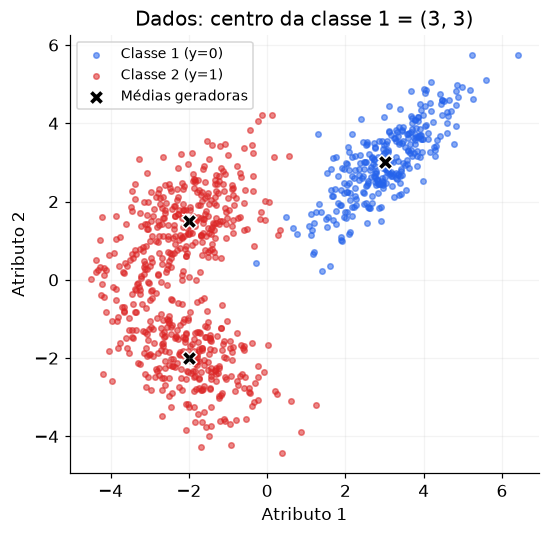

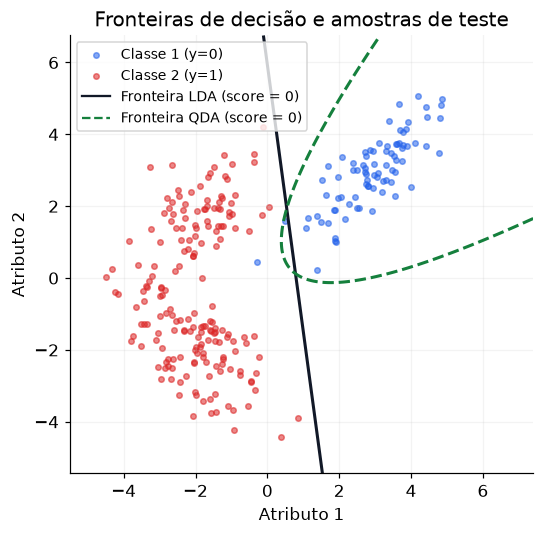

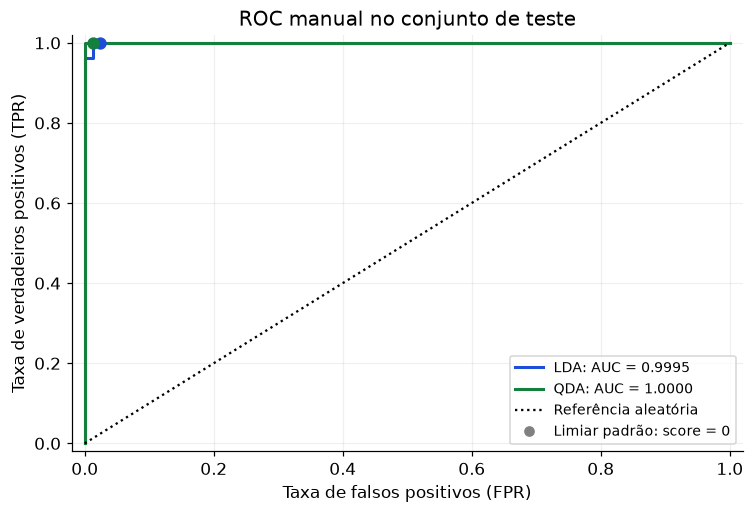

,Acurácia,TP,FP,TN,FN,AUC manual
Modelo,,,,,,
LDA,0.992593,187,2,81,0,0.999549
QDA,0.996296,187,1,82,0,1.000000


QDA obteve maior acurácia, com vantagem de 0.37 pontos percentuais. LDA: acurácia 99.26%, AUC 0.9995; QDA: acurácia 99.63%, AUC 1.0000.

Acurácia   TP  FP  TN  FN  AUC manual
Cenário          Modelo                                       
Original (0, 0)  LDA     0.844444  165  20  63  22    0.913214
                 QDA     0.940741  187  16  67   0    0.972747
Deslocado (3, 3) LDA     0.992593  187   2  81   0    0.999549
                 QDA     0.996296  187   1  82   0    1.000000

In [6]:
X_deslocado = X.copy()
X_deslocado[y == 0] += [3, 3]
grafico_dados(X_deslocado, 'deslocado', (3, 3))
modelos_deslocado = ajustar(X_deslocado)
metricas_deslocado = metricas(X_deslocado, modelos_deslocado)
fronteiras(X_deslocado, modelos_deslocado, 'deslocado')
metricas_deslocado = comparar_roc(X_deslocado, modelos_deslocado, 'deslocado', metricas_deslocado)
display(metricas_deslocado)
display(Markdown(conclusao(metricas_deslocado)))
comparacao = pd.concat({'Original (0, 0)': metricas_original,
                       'Deslocado (3, 3)': metricas_deslocado}, names=['Cenário'])
display(comparacao)


O deslocamento afasta a classe 1 dos dois componentes da classe 2 e reduz a
sobreposição. A fronteira linear passa a separar os grupos mais facilmente;
a flexibilidade extra do QDA tende a trazer menos benefício. As covariâncias
continuam diferentes e a classe 2 continua sendo uma mistura: aumentar a
separação não torna as hipóteses gaussianas mais verdadeiras. Um eventual
resultado perfeito nesta amostra não garante erro zero em novos dados, pois
as distribuições gaussianas têm suporte ilimitado.


## Verificação e exportação

Conferimos a ROC com exemplos de ordenação perfeita, invertida e empatada;
verificamos extremos, monotonicidade, conservação das contagens e AUC com
uma segunda definição independente (comparação de todos os pares positivo/negativo).
Os arquivos CSV guardam todos os limiares e contagens para inspeção.


In [7]:
for scores, esperado in [([0, 1], 1.), ([1, 0], 0.), ([1, 1], .5)]:
    _, area = roc_manual([0, 1], scores)
    np.testing.assert_allclose(area, esperado)
assert X.shape == (900, 2) and len(treino) == 630 and len(teste) == 270
assert len(set(treino) & set(teste)) == 0
np.testing.assert_allclose(X_deslocado[y == 0] - X[y == 0], np.full((n, 2), 3.))
np.testing.assert_array_equal(X_deslocado[y == 1], X[y == 1])
for dados, modelos in [(X, modelos_original), (X_deslocado, modelos_deslocado)]:
    for modelo in modelos.values():
        scores = modelo.decision_function(dados[teste])
        curva, area = roc_manual(y[teste], scores)
        np.testing.assert_allclose(curva[['FPR', 'TPR']].iloc[[0, -1]], [[0, 0], [1, 1]])
        assert np.all(np.diff(curva.FPR) >= 0) and np.all(np.diff(curva.TPR) >= 0)
        assert np.all(curva.TP + curva.FN == np.sum(y[teste] == 1))
        assert np.all(curva.FP + curva.TN == np.sum(y[teste] == 0))
        positivos, negativos = scores[y[teste] == 1], scores[y[teste] == 0]
        pares = positivos[:, None] - negativos[None, :]
        area_pares = np.mean((pares > 0) + .5 * (pares == 0))
        np.testing.assert_allclose(area, area_pares)
        np.testing.assert_array_equal(modelo.predict(dados[teste]), (scores > 0).astype(int))

resultados = {
    'original': metricas_original.reset_index().to_dict(orient='records'),
    'deslocado': metricas_deslocado.reset_index().to_dict(orient='records'),
    'contagens': contagens.to_dict(),
    'versoes': {'python': platform.python_version(), 'numpy': np.__version__,
                'pandas': pd.__version__, 'scikit-learn': sklearn.__version__},
}
(OUTPUT / 'resultados.json').write_text(json.dumps(resultados, indent=2, ensure_ascii=False), encoding='utf-8')
print('Todas as verificações passaram. Resultados exportados para output/.')


Todas as verificações passaram. Resultados exportados para output/.
